<a href="https://colab.research.google.com/github/tomasgrzn6-cmyk/zero-to-quant/blob/main/MonteCarlo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipykernel_7412/4220541748.py:32: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  S0 = float(prices.iloc[-1])
/tmp/ipykernel_7412/4220541748.py:35: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  mu = float(log_returns.mean() * 252)      # annualized drift
/tmp/ipykernel_7412/4220541748.py:36: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  sigma = float(log_returns.std() * np.sqrt(252))  # annualized volatility


S0=349.51  mu=0.2297  sigma=0.2883

After 30 trading days, 10000 simulations:
  Mean price:        359.20
  Median price:       357.14
  5th percentile:    304.27
  95th percentile:   420.94
  P(price < S0):     41.2%
  95% VaR (return):  12.94%
  95% Expected Shortfall: 16.56%


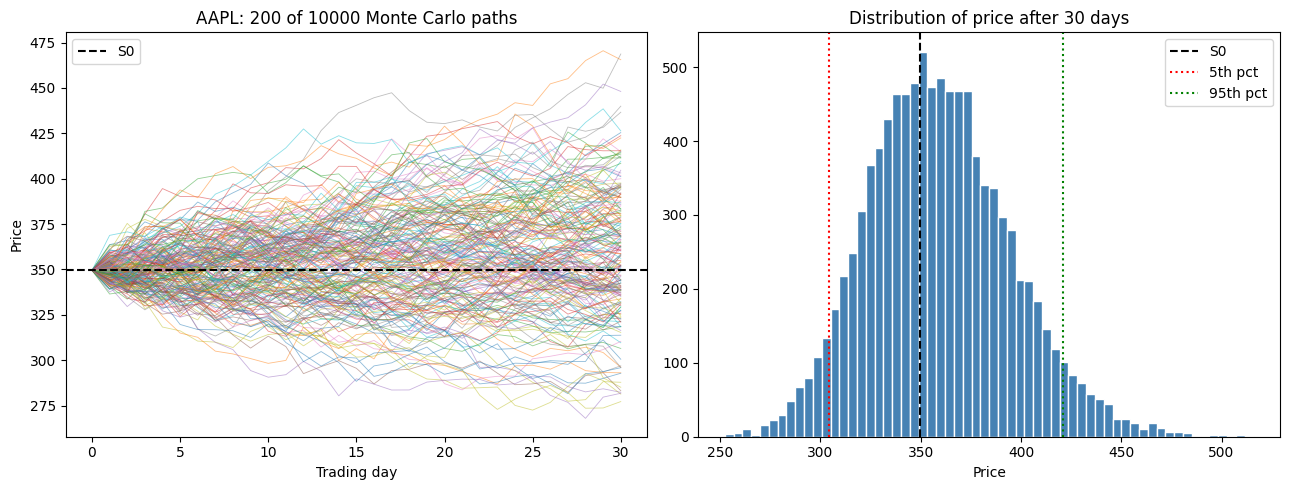

In [ ]:
"""
Monte Carlo simulation of a stock price over the next N days
using Geometric Brownian Motion (GBM).

Model:
    S_{t+1} = S_t * exp( (mu - 0.5*sigma^2)*dt + sigma*sqrt(dt)*Z )

where:
    mu    = expected annual drift (return)
    sigma = annual volatility
    dt    = 1/252 (one trading day)
    Z     ~ N(0,1)

Requires: numpy, matplotlib, (optional) yfinance for real historical data.
    pip install numpy matplotlib yfinance
"""

import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# 1. Get data: either pull real history with yfinance, or set manually
# ---------------------------------------------------------------
USE_YFINANCE = True
TICKER = "AAPL"

if USE_YFINANCE:
    import yfinance as yf

    hist = yf.download(TICKER, period="2y", auto_adjust=True, progress=False)
    prices = hist["Close"].dropna()
    S0 = float(prices.iloc[-1])

    log_returns = np.log(prices / prices.shift(1)).dropna()
    mu = float(log_returns.mean() * 252)      # annualized drift
    sigma = float(log_returns.std() * np.sqrt(252))  # annualized volatility
else:
    # Manual fallback: plug in your own numbers
    S0 = 100.0     # current price
    mu = 0.08      # 8% expected annual return
    sigma = 0.25   # 25% annual volatility

print(f"S0={S0:.2f}  mu={mu:.4f}  sigma={sigma:.4f}")

# ---------------------------------------------------------------
# 2. Monte Carlo simulation
# ---------------------------------------------------------------
n_days = 30
n_sims = 10_000
dt = 1 / 252

rng = np.random.default_rng(seed=42)
Z = rng.standard_normal((n_days, n_sims))

daily_returns = (mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z
log_paths = np.vstack([np.zeros(n_sims), np.cumsum(daily_returns, axis=0)])
paths = S0 * np.exp(log_paths)   # shape: (n_days+1, n_sims)

final_prices = paths[-1]

# ---------------------------------------------------------------
# 3. Statistics / risk metrics
# ---------------------------------------------------------------
mean_final = final_prices.mean()
median_final = np.median(final_prices)
p5, p95 = np.percentile(final_prices, [5, 95])
prob_loss = (final_prices < S0).mean()

# Value at Risk (95%) and Expected Shortfall on returns
returns = final_prices / S0 - 1
VaR_95 = -np.percentile(returns, 5)
ES_95 = -returns[returns <= np.percentile(returns, 5)].mean()

print(f"\nAfter {n_days} trading days, {n_sims} simulations:")
print(f"  Mean price:        {mean_final:.2f}")
print(f"  Median price:       {median_final:.2f}")
print(f"  5th percentile:    {p5:.2f}")
print(f"  95th percentile:   {p95:.2f}")
print(f"  P(price < S0):     {prob_loss*100:.1f}%")
print(f"  95% VaR (return):  {VaR_95*100:.2f}%")
print(f"  95% Expected Shortfall: {ES_95*100:.2f}%")

# ---------------------------------------------------------------
# 4. Plots
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Sample paths
axes[0].plot(paths[:, :200], linewidth=0.6, alpha=0.5)
axes[0].axhline(S0, color="black", linestyle="--", label="S0")
axes[0].set_title(f"{TICKER if USE_YFINANCE else 'Stock'}: 200 of {n_sims} Monte Carlo paths")
axes[0].set_xlabel("Trading day")
axes[0].set_ylabel("Price")
axes[0].legend()

# Distribution of final prices
axes[1].hist(final_prices, bins=60, color="steelblue", edgecolor="white")
axes[1].axvline(S0, color="black", linestyle="--", label="S0")
axes[1].axvline(p5, color="red", linestyle=":", label="5th pct")
axes[1].axvline(p95, color="green", linestyle=":", label="95th pct")
axes[1].set_title(f"Distribution of price after {n_days} days")
axes[1].set_xlabel("Price")
axes[1].legend()

plt.tight_layout()
plt.savefig("monte_carlo_result.png", dpi=150)
plt.show()